# Benchmark study: what the published baselines show before building a method

**Goal.** Before choosing our method, look at the results the MulTaBench authors already computed for the
20 text-tabular datasets, and answer three questions:
1. How much does **Joint TAR** (fine-tuning the text encoder on the target) actually gain over **Joint Frozen**?
2. How noisy are the scores, i.e. how big must an improvement be before we can believe it?
3. How hard is our planned statistical test to pass?

**No models are trained here.** Everything comes from upstream's precomputed CSVs
(`multabench/leaderboard/results/text/`) — 20 datasets × 5 learners × 4 conditions × 5 folds.
All the logic lives in `scripts/phase0_diagnostics.py`; this notebook only calls it and draws pictures.

**Vocabulary.**
| Condition | Upstream name | What the learner sees |
|---|---|---|
| Unimodal Structured | `no_text` | only numbers/categories; text columns dropped |
| Unimodal Text | `text_only` | only text, as frozen E5 embeddings (→ PCA 30 per column) |
| Joint Frozen | `all` | structured columns + frozen E5 text embeddings |
| Joint TAR | `ft` | structured columns + embeddings from an E5 fine-tuned (LoRA) on this dataset's target |

**Learners**: CatBoost, LightGBM (gradient-boosted trees), TabM (a neural net), TabPFN-v2 / v2.5 (pretrained
"foundation" models). **Score**: AUROC for classification, R² for regression — higher is better for both,
1.0 is perfect. **Fold**: one of 5 different random train/test splits; every condition uses the *same* 5 splits.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

from scripts.phase0_diagnostics import (
    LEARNERS, baseline_noise, dataset_overview, friendly_names, gain_table, headroom, load_results,
    significance_baseline,
)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 4)

# Chart styling: recessive axes, text in ink colors (never series colors).
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, ORANGE, AQUA, RED, NEUTRAL = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#f0efec"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID, "axes.labelcolor": INK_2,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 9, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

results = load_results()
names = friendly_names()
TASK_ORDER = {"binary": 0, "multiclass": 1, "regression": 2}
print(f"{len(results)} runs | {results.dataset.nunique()} datasets | learners: {sorted(results.learner.unique())}")
print("runs per condition:", results.groupby("state").size().to_dict())

1920 runs | 20 datasets | learners: ['CatBoost', 'LightGBM', 'TabM', 'TabPFN-v2', 'TabPFN-v2p5']
runs per condition: {'all': 480, 'ft': 480, 'no_text': 480, 'text_only': 480}


## a) The 20 datasets

Each dataset is a table with some **structured** columns (numbers, categories) and some **text** columns
(free text like a review, a job description, a book synopsis). *N* is the number of rows before the benchmark
caps it (train ≤ 10,000, test = 10% capped at 2,000). Classification tasks report the number of classes.

In [2]:
overview, text_lengths = dataset_overview()
overview.insert(0, "order", overview["task"].map(TASK_ORDER))
overview = overview.sort_values(["order", "dataset"]).drop(columns="order").reset_index(drop=True)
display(overview)
print(overview.groupby("task").size().to_dict(), "| median #text cols:", overview.n_text_cols.median(),
      "| median #structured cols:", overview.n_struct_cols.median())

,dataset,name,task,classes,N,n_struct_cols,n_text_cols,raw_cached
0,BIN_TEXT_FAKE_JOB_POSTING,Fake Job Postings,binary,2,12725,2,3,False
1,BIN_TEXT_JIGSAW_TOXICITY,Jigsaw Toxicity,binary,2,100000,30,1,False
2,BIN_TEXT_KICKSTARTER_FUNDING,Kickstarter,binary,2,86502,6,3,False
3,MUL_TEXT_DATA_SCIENTIST_SALARY,Data Scientist Salary,multiclass,6,15841,1,5,False
4,MUL_TEXT_MICHELIN_RESTAURANTS,Michelin Guide,multiclass,5,18843,5,6,False
5,MUL_TEXT_PRODUCT_SENTIMENT,Product Sentiment,multiclass,4,5091,1,1,False
6,MUL_TEXT_SPOTIFY_GENRES,Spotify Genres,multiclass,114,114000,15,3,False
7,MUL_TEXT_US_ACCIDENTS,US Accidents,multiclass,4,100001,38,6,False
8,MUL_TEXT_WINE_REVIEW,Wine Review,multiclass,30,84123,3,2,False
9,MUL_TEXT_WOMEN_CLOTHING_REVIEW,Women's Clothing,multiclass,5,18788,8,2,False


{'binary': 3, 'multiclass': 7, 'regression': 10} | median #text cols: 3.5 | median #structured cols: 5.5


**Text length** (characters per text cell) can only be measured from the raw data. Downloading all 20
datasets is out of scope here, so we only measure datasets already in the local Kaggle cache.

In [3]:
cached = overview.loc[overview.raw_cached, "name"].tolist()
print(f"Raw data cached locally for {len(cached)} of {len(overview)} datasets: {cached}")
print("Text-length statistics for the other datasets are skipped (not downloaded).")
display(text_lengths)

Raw data cached locally for 1 of 20 datasets: ['Book Price']
Text-length statistics for the other datasets are skipped (not downloaded).


,dataset,column,n_nonnull,mean_chars,median_chars,max_chars
0,REG_TEXT_BOOK_PRICE,Synopsis,4989,1000.2758,906.0,6240
1,REG_TEXT_BOOK_PRICE,Edition,4989,23.6991,23.0,47
2,REG_TEXT_BOOK_PRICE,Author,4989,14.3331,13.0,87
3,REG_TEXT_BOOK_PRICE,Title,4989,44.4406,38.0,199
4,REG_TEXT_BOOK_PRICE,Genre,4989,24.5324,26.0,56


## b) Gain table: how much does fine-tuning the text encoder help? (Joint TAR − Joint Frozen)

For each dataset × learner we compute, **per fold**, `gain = TAR score − Frozen score` (same split for both), then
average over the 5 folds. We also flag cells where `|gain|` is larger than the fold-to-fold std of TAR's own
score — a rough "is this bigger than ordinary split noise?" check (`*` in the heatmap).

In [4]:
gains = gain_table(results)
gains["name"] = gains["dataset"].map(names)
display(gains[["name", "task", "learner", "frozen_mean", "frozen_std", "tar_mean", "tar_std",
               "gain_mean", "gain_std", "gain_folds_positive", "exceeds_fold_std"]])
print(f"cells with gain > 0: {(gains.gain_mean > 0).sum()} / {len(gains)} | "
      f"cells where |gain| > fold std: {gains.exceeds_fold_std.sum()} / {len(gains)}")

,name,task,learner,frozen_mean,frozen_std,tar_mean,tar_std,gain_mean,gain_std,gain_folds_positive,exceeds_fold_std
0,Fake Job Postings,binary,CatBoost,0.9058,0.0165,0.9118,0.0168,0.0060,0.0183,3,False
1,Fake Job Postings,binary,LightGBM,0.9093,0.0200,0.9190,0.0138,0.0097,0.0213,4,False
2,Fake Job Postings,binary,TabM,0.9333,0.0126,0.9262,0.0165,-0.0070,0.0132,1,False
3,Fake Job Postings,binary,TabPFN-v2,0.9135,0.0224,0.9186,0.0174,0.0051,0.0088,3,False
4,Fake Job Postings,binary,TabPFN-v2p5,0.9452,0.0134,0.9295,0.0126,-0.0158,0.0068,0,True
...,...,...,...,...,...,...,...,...,...,...,...
91,Zomato Restaurants,regression,CatBoost,0.8251,0.0039,0.8404,0.0047,0.0152,0.0070,5,True
92,Zomato Restaurants,regression,LightGBM,0.7782,0.0055,0.8049,0.0060,0.0268,0.0069,5,True
93,Zomato Restaurants,regression,TabM,0.8442,0.0057,0.8518,0.0043,0.0076,0.0058,5,True
94,Zomato Restaurants,regression,TabPFN-v2,0.7158,0.0106,0.7443,0.0097,0.0285,0.0028,5,True


cells with gain > 0: 88 / 96 | cells where |gain| > fold std: 41 / 96


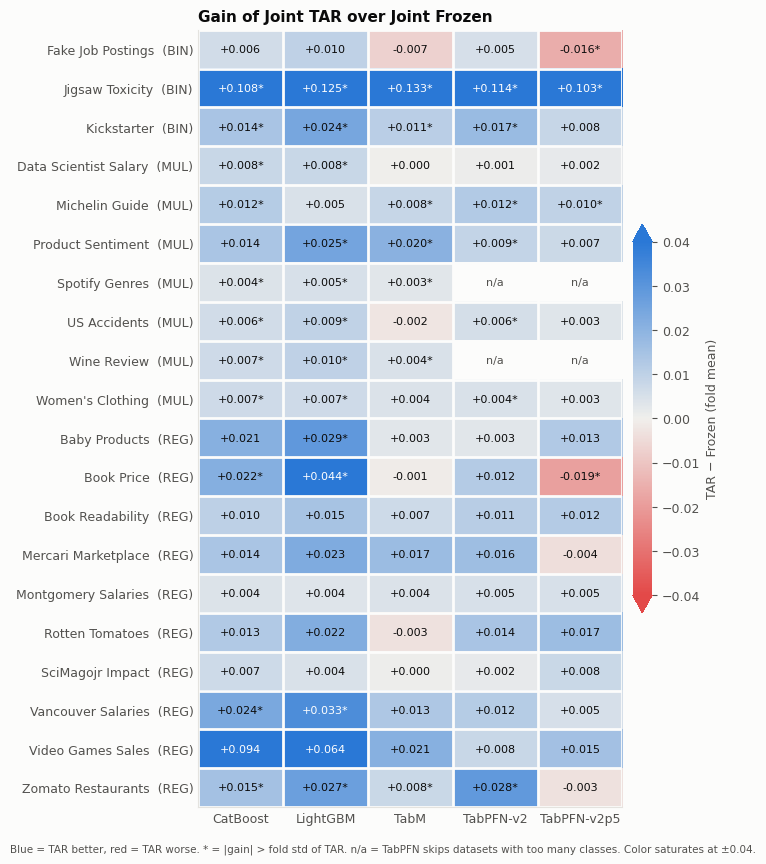

In [5]:
row_order = (overview.assign(o=overview.task.map(TASK_ORDER)).sort_values(["o", "name"])["dataset"].tolist())
heat = gains.pivot(index="dataset", columns="learner", values="gain_mean").loc[row_order, LEARNERS]
flag = gains.pivot(index="dataset", columns="learner", values="exceeds_fold_std").loc[row_order, LEARNERS]

LIM = 0.04  # color saturates here so Jigsaw (+0.117) doesn't wash out everything else; numbers show true values
cmap = LinearSegmentedColormap.from_list("div", [RED, NEUTRAL, BLUE])
fig, ax = plt.subplots(figsize=(7.2, 8.6))
im = ax.imshow(heat.to_numpy(dtype=float), cmap=cmap, norm=TwoSlopeNorm(vmin=-LIM, vcenter=0, vmax=LIM), aspect="auto")
ax.grid(False)
for i, ds in enumerate(row_order):
    for j, lr in enumerate(LEARNERS):
        v = heat.loc[ds, lr]
        if pd.isna(v):
            ax.text(j, i, "n/a", ha="center", va="center", color=INK_2, fontsize=8)
            continue
        star = "*" if flag.loc[ds, lr] else ""
        ax.text(j, i, f"{v:+.3f}{star}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.75 * LIM else INK)
ax.set_xticks(range(len(LEARNERS)), LEARNERS)
ax.set_yticks(range(len(row_order)), [f"{names[d]}  ({d[:3]})" for d in row_order])
ax.tick_params(length=0)
ax.set_xticks(np.arange(-.5, len(LEARNERS)), minor=True); ax.set_yticks(np.arange(-.5, len(row_order)), minor=True)
ax.grid(which="minor", color=SURFACE, linewidth=2); ax.tick_params(which="minor", length=0)
cb = fig.colorbar(im, ax=ax, shrink=0.5, pad=0.02, extend="both")
cb.set_label("TAR − Frozen (fold mean)", color=INK_2); cb.outline.set_visible(False)
ax.set_title("Gain of Joint TAR over Joint Frozen")
fig.text(0.01, 0.005, "Blue = TAR better, red = TAR worse. * = |gain| > fold std of TAR. n/a = TabPFN skips "
         "datasets with too many classes. Color saturates at ±0.04.", fontsize=7.5, color=INK_2)
plt.tight_layout(rect=(0, 0.02, 1, 1)); plt.show()

**How to read it.** Almost everything is blue: fine-tuning helps nearly everywhere, but usually by
only +0.005 to +0.02. Jigsaw Toxicity is the outlier (≈ +0.12): toxicity is a property of the text that a generic
embedding doesn't capture, so target-aware fine-tuning matters a lot there. The few red cells are tiny.

## c) Headroom: is Joint TAR already the best thing you can do with these four conditions?

For each learner we look at which of the four conditions scores best; **headroom = best − TAR** (0 if TAR is
best). If headroom were large, e.g. because dropping the text helps, a smarter way of *combining* modalities would
be an easy win. We also compare **structured only vs text only**, to see which source carries more signal.
All numbers are averaged over the learners.

In [6]:
hr = headroom(results)
hr["name"] = hr["dataset"].map(names)
display(hr[["name", "task", "struct", "text", "frozen", "tar", "headroom", "learners_tar_is_best",
            "most_common_best", "text_minus_struct"]])
print(f"TAR is the best condition in {hr.learners_tar_is_best.sum()} of {hr.n_learners.sum()} dataset×learner cells | "
      f"text beats structured on {(hr.text_minus_struct > 0).sum()} / {len(hr)} datasets")
best_uni = hr[["struct", "text"]].max(axis=1)
print(f"Joint Frozen − best unimodal: median {np.median(hr.frozen - best_uni):+.4f}, "
      f"max {(hr.frozen - best_uni).max():+.4f} ({hr.loc[(hr.frozen - best_uni).idxmax(), 'name']})")

,name,task,struct,text,frozen,tar,headroom,learners_tar_is_best,most_common_best,text_minus_struct
0,Fake Job Postings,binary,0.6791,0.9100,0.9214,0.9210,0.0046,3,Joint TAR,0.2309
1,Jigsaw Toxicity,binary,0.5608,0.8081,0.8145,0.9310,0.0000,5,Joint TAR,0.2473
2,Kickstarter,binary,0.6093,0.7003,0.7304,0.7454,0.0000,5,Joint TAR,0.0910
3,Data Scientist Salary,multiclass,0.5542,0.8217,0.8246,0.8284,0.0000,5,Joint TAR,0.2675
4,Michelin Guide,multiclass,0.8707,0.8644,0.9075,0.9168,0.0000,5,Joint TAR,-0.0062
5,Product Sentiment,multiclass,0.8264,0.7881,0.9006,0.9156,0.0000,5,Joint TAR,-0.0383
6,Spotify Genres,multiclass,0.9024,0.8962,0.9388,0.9427,0.0000,3,Joint TAR,-0.0062
7,US Accidents,multiclass,0.8611,0.9668,0.9726,0.9770,0.0005,4,Joint TAR,0.1057
8,Wine Review,multiclass,0.8472,0.9707,0.9726,0.9797,0.0000,3,Joint TAR,0.1234
9,Women's Clothing,multiclass,0.7788,0.8882,0.9047,0.9098,0.0000,5,Joint TAR,0.1094


TAR is the best condition in 88 of 96 dataset×learner cells | text beats structured on 15 / 20 datasets
Joint Frozen − best unimodal: median +0.0262, max +0.1710 (Vancouver Salaries)


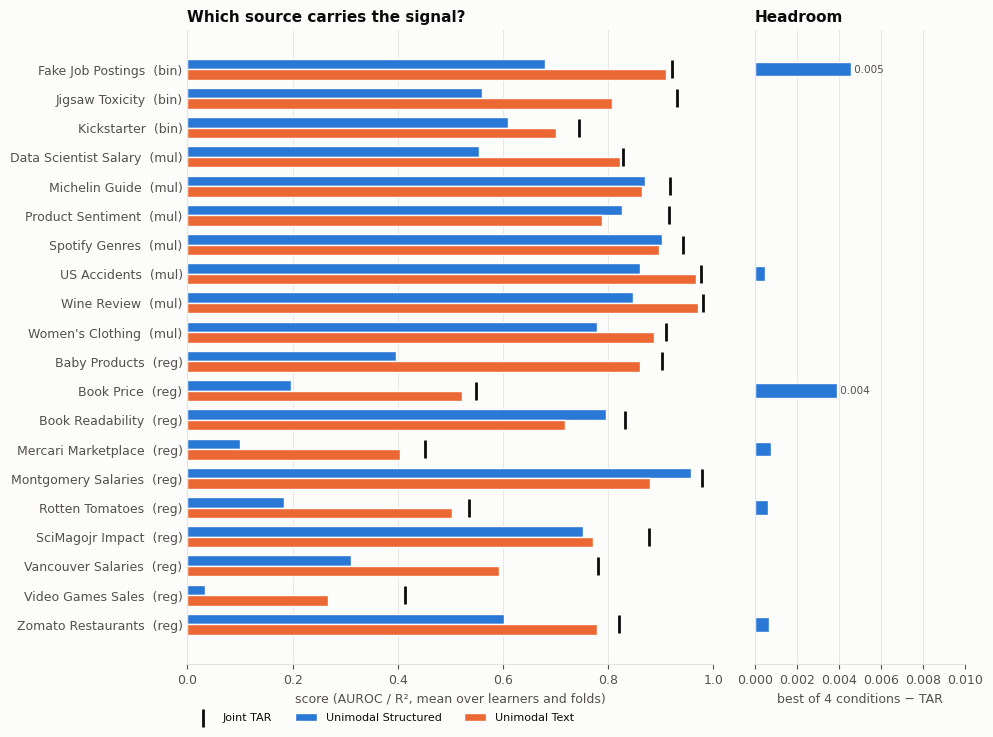

In [7]:
h = hr.assign(o=hr.task.map(TASK_ORDER)).sort_values(["o", "name"], ascending=False).reset_index(drop=True)
y = np.arange(len(h))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 7.4), sharey=True, gridspec_kw={"width_ratios": [3, 1.2]})
bh = 0.36
ax1.barh(y + bh / 2, h["struct"], height=bh, color=BLUE, edgecolor=SURFACE, linewidth=1, label="Unimodal Structured")
ax1.barh(y - bh / 2, h["text"], height=bh, color=ORANGE, edgecolor=SURFACE, linewidth=1, label="Unimodal Text")
ax1.scatter(h["tar"], y, marker="|", s=160, linewidths=2, color=INK, zorder=3, label="Joint TAR")
ax1.set_yticks(y, [f"{n}  ({t[:3]})" for n, t in zip(h["name"], h["task"])])
ax1.set_xlim(0, 1.0); ax1.grid(axis="y", visible=False); ax1.tick_params(axis="y", length=0)
ax1.set_xlabel("score (AUROC / R², mean over learners and folds)")
ax1.set_title("Which source carries the signal?")
ax1.legend(loc="upper left", bbox_to_anchor=(0, -0.07), ncol=3, frameon=False, fontsize=8, scatterpoints=1, borderaxespad=0)
ax2.barh(y, h["headroom"], height=0.5, color=BLUE, edgecolor=SURFACE)
ax2.set_xlim(0, max(0.01, h["headroom"].max() * 1.3)); ax2.grid(axis="y", visible=False); ax2.tick_params(axis="y", length=0)
ax2.set_xlabel("best of 4 conditions − TAR")
ax2.set_title("Headroom")
for yi, v in zip(y, h["headroom"]):
    if v > 0.002:
        ax2.text(v, yi, f" {v:.3f}", va="center", fontsize=7.5, color=INK_2)
plt.tight_layout(); plt.show()

**How to read it.** Left: the black tick (TAR) sits to the right of *both* bars on almost every
row, i.e. combining structured + text beats either alone, sometimes by a lot (Vancouver Salaries, SCImago
Impact). Right: headroom is ≈ 0 everywhere — TAR is already the best of the four conditions, so there is nothing to
gain by simply dropping a modality. Any improvement has to come from **better text representations**.

## d) Baseline noise: how small an improvement could we detect?

Scores move from fold to fold just because the train/test split changes. Two numbers per dataset:
- **`tar_fold_std`** — how much TAR's own score varies across the 5 folds.
- **`paired_diff_std`** — how much the *difference* (TAR − Frozen) varies across folds. Two methods run on the
  same splits share most of the split noise, so differences are much less noisy than raw scores. This is the
  noise level that matters when we compare *our method vs TAR*.

From that, **`mde_paired`** ("minimum detectable effect") = the smallest average gain over 5 folds that a paired
t-test would call significant *on that dataset alone*: `t(0.975, 4) × paired_diff_std / √5 ≈ 1.24 × paired_diff_std`.
`mde_unpaired` shows what it would be if we ignored the pairing.

In [8]:
noise = baseline_noise(results)
noise["name"] = noise["dataset"].map(names)
noise = noise.merge(gains.groupby("dataset", as_index=False)["gain_mean"].mean().rename(columns={"gain_mean": "tar_gain"}))
display(noise[["name", "task", "tar_mean", "tar_fold_std", "paired_diff_std", "mde_paired", "mde_unpaired", "tar_gain"]])
print(f"median mde_paired = {noise.mde_paired.median():.4f} | median mde_unpaired = {noise.mde_unpaired.median():.4f} | "
      f"TAR's own gain exceeds mde_paired on {(noise.tar_gain > noise.mde_paired).sum()} / {len(noise)} datasets")

,name,task,tar_mean,tar_fold_std,paired_diff_std,mde_paired,mde_unpaired,tar_gain
0,Fake Job Postings,binary,0.9210,0.0154,0.0137,0.0170,0.0225,-0.0004
1,Jigsaw Toxicity,binary,0.9310,0.0099,0.0255,0.0316,0.0144,0.1166
2,Kickstarter,binary,0.7454,0.0128,0.0081,0.0100,0.0187,0.0150
3,Data Scientist Salary,multiclass,0.8284,0.0040,0.0035,0.0044,0.0058,0.0038
4,Michelin Guide,multiclass,0.9168,0.0057,0.0032,0.0040,0.0083,0.0093
5,Product Sentiment,multiclass,0.9156,0.0145,0.0114,0.0141,0.0211,0.0150
6,Spotify Genres,multiclass,0.9427,0.0022,0.0009,0.0011,0.0033,0.0039
7,US Accidents,multiclass,0.9770,0.0071,0.0056,0.0070,0.0103,0.0044
8,Wine Review,multiclass,0.9797,0.0017,0.0013,0.0016,0.0025,0.0070
9,Women's Clothing,multiclass,0.9098,0.0046,0.0023,0.0028,0.0068,0.0051


median mde_paired = 0.0098 | median mde_unpaired = 0.0181 | TAR's own gain exceeds mde_paired on 10 / 20 datasets


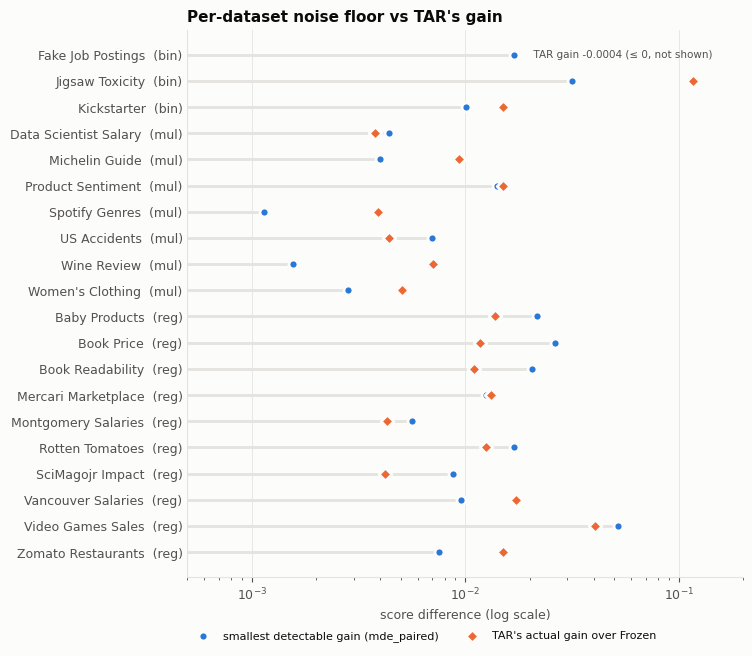

In [9]:
n = noise.assign(o=noise.task.map(TASK_ORDER)).sort_values(["o", "name"], ascending=False).reset_index(drop=True)
y = np.arange(len(n))
fig, ax = plt.subplots(figsize=(7.6, 6.6))
ax.hlines(y, 0, n["mde_paired"], color=GRID, linewidth=2, zorder=1)
ax.scatter(n["mde_paired"], y, s=42, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3, label="smallest detectable gain (mde_paired)")
ax.scatter(n["tar_gain"], y, s=42, marker="D", color=ORANGE, edgecolor=SURFACE, linewidth=2, zorder=3, label="TAR's actual gain over Frozen")
ax.set_yticks(y, [f"{a}  ({t[:3]})" for a, t in zip(n["name"], n["task"])]); ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False); ax.set_xscale("log"); ax.set_xlim(5e-4, 0.2)
ax.set_xlabel("score difference (log scale)")
for yi, (g_, m_) in enumerate(zip(n["tar_gain"], n["mde_paired"])):
    if g_ <= 0:  # a log axis can't show it, so say so instead of silently dropping the point
        ax.text(m_ * 1.15, yi, f"  TAR gain {g_:+.4f} (≤ 0, not shown)", va="center", fontsize=7.5, color=INK_2)
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.09), ncol=2, frameon=False, fontsize=8, scatterpoints=1, borderaxespad=0)
ax.set_title("Per-dataset noise floor vs TAR's gain")
plt.tight_layout(); plt.show()

**How to read it.** Where the orange diamond is right of the blue dot, TAR's gain over Frozen is
detectable on that dataset alone. That's only about half the datasets — on a single dataset, gains of ~0.01 are
mostly invisible. This is why we test **across** datasets (next section) rather than dataset by dataset.

## e) Does the baseline itself pass our planned test?

Our pre-registered test (claim C1 in the lab notebook, [`archive/PROGRESS.md`](../archive/PROGRESS.md)): per learner, take one number per dataset — the fold-averaged
difference — and run a **two-sided Wilcoxon signed-rank test** across datasets, p < 0.05.

*Wilcoxon in one paragraph:* rank the datasets by |difference|, then add up the ranks of the datasets where the
method **lost**. If that sum (W) is small, losses are rare and/or tiny, so the method is consistently better.
`w_critical` is the largest W that still counts as significant (52 for 20 datasets, 40 for 18).

Here we apply it to **TAR − Frozen**: this is exactly the kind of win the course asks us to produce on top of TAR.

In [10]:
sig = significance_baseline(results)
display(sig)

,learner,n_datasets,mean_diff,median_diff,ci95_low,ci95_high,n_positive,wilcoxon_W,w_critical,p_value,significant
0,CatBoost,20,0.0204,0.0121,0.0103,0.0340,20,0.0,52,1.9073e-06,True
1,LightGBM,20,0.0246,0.0184,0.0144,0.0381,20,0.0,52,1.9073e-06,True
2,TabM,20,0.0122,0.0043,0.0034,0.0264,16,25.0,52,1.6899e-03,True
3,TabPFN-v2,18,0.0155,0.0100,0.0076,0.0287,18,0.0,40,7.6294e-06,True
4,TabPFN-v2p5,18,0.0094,0.0063,0.0003,0.0224,14,41.0,40,5.3856e-02,False


**How to read it.** For CatBoost, LightGBM and TabPFN-v2, TAR beats Frozen on *every* dataset
(W = 0). TabM wins on 16/20 and is still significant. TabPFN-v2.5 wins on 14/18 with W = 41 vs a critical value of
40 — it misses by one rank. So even a well-established, consistent improvement of ~+0.01 only *just* clears this
bar for some learners.

In [11]:
def _f(x): return f"{x:+.4f}"
s = sig.set_index("learner")
med_gain = noise.tar_gain.median()
print("Numbers used in the final cell:")
print(f"  significant learners: {int(s.significant.sum())}/5 | p-values:", {k: round(v, 4) for k, v in s.p_value.items()})
print(f"  mean diff per learner:", {k: round(v, 4) for k, v in s.mean_diff.items()})
print(f"  median TAR gain over datasets {_f(med_gain)} | without Jigsaw mean "
      f"{_f(noise.loc[noise.dataset != 'BIN_TEXT_JIGSAW_TOXICITY', 'tar_gain'].mean())}")
print(f"  median mde_paired {noise.mde_paired.median():.4f}")
print(f"  TAR best condition: {hr.learners_tar_is_best.sum()}/{hr.n_learners.sum()} cells | text > struct on {(hr.text_minus_struct > 0).sum()}/20")
print(f"  regression datasets: {(overview.task == 'regression').sum()}/20")

Numbers used in the final cell:
  significant learners: 4/5 | p-values: {'CatBoost': 0.0, 'LightGBM': 0.0, 'TabM': 0.0017, 'TabPFN-v2': 0.0, 'TabPFN-v2p5': 0.0539}
  mean diff per learner: {'CatBoost': 0.0204, 'LightGBM': 0.0246, 'TabM': 0.0122, 'TabPFN-v2': 0.0155, 'TabPFN-v2p5': 0.0094}
  median TAR gain over datasets +0.0113 | without Jigsaw mean +0.0109
  median mde_paired 0.0098
  TAR best condition: 88/96 cells | text > struct on 15/20
  regression datasets: 10/20


## f) What this means for choosing our idea

1. **TAR is a strong, consistent baseline.** It beats Frozen significantly for 4 of 5 learners (p < 0.002); for
   CatBoost, LightGBM and TabPFN-v2 it wins on every dataset. TabPFN-v2.5 misses (p = 0.054, 14/18 wins).
2. **But the gains are small.** Median gain over datasets is ≈ +0.011 (mean +0.009 to +0.025 per learner; Jigsaw
   alone is +0.117). Our method has to add *another* step of about this size on top of TAR.
3. **Per-dataset noise is about as big as the gain** (median detectable gain ≈ 0.010), so we will win through
   **consistency across datasets**, not big wins on a few: with 20 datasets, the losses' rank sum must stay ≤ 52
   (roughly 4–5 losses of typical size, or more if they are tiny).
4. **Nothing to gain by dropping a modality** — TAR is the best of the 4 conditions in 88/96 cells. The
   improvement must come from **better text representations**.
5. **Text and structure are complementary**: Joint beats the best single source by a median of +0.026 (up to
   +0.171 on Vancouver Salaries), and text beats structure on 15/20 datasets. TAR's encoder never sees the
   structured columns → this supports **A (context-aware TAR)** and **B (residual TAR)**.
6. **D (ordinal loss)** only changes the 10 regression datasets; on the other 10 it equals TAR, so alone it can
   hardly move a 20-dataset test → fine as an add-on, not as the main idea.
7. **C (cross-fitting)** fixes a real leakage-like bias, but the CSVs can't show how big it is (gain is unrelated
   to dataset size, Spearman ≈ 0.02, since training is capped at 10k anyway) → needs a direct pilot experiment.
8. **Learners react differently**: trees gain most from TAR (+0.020/+0.025), TabPFN-v2.5 least (+0.009). We need
   significance for ≥ 3 of 5 learners, so the method must not rely on one learner family.
9. **Suggestion to discuss:** A or B as the main idea (they target the complementarity in point 5), with C as a
   cheap add-on; run a small pilot on 4–5 datasets before pre-registering the full claim.